Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


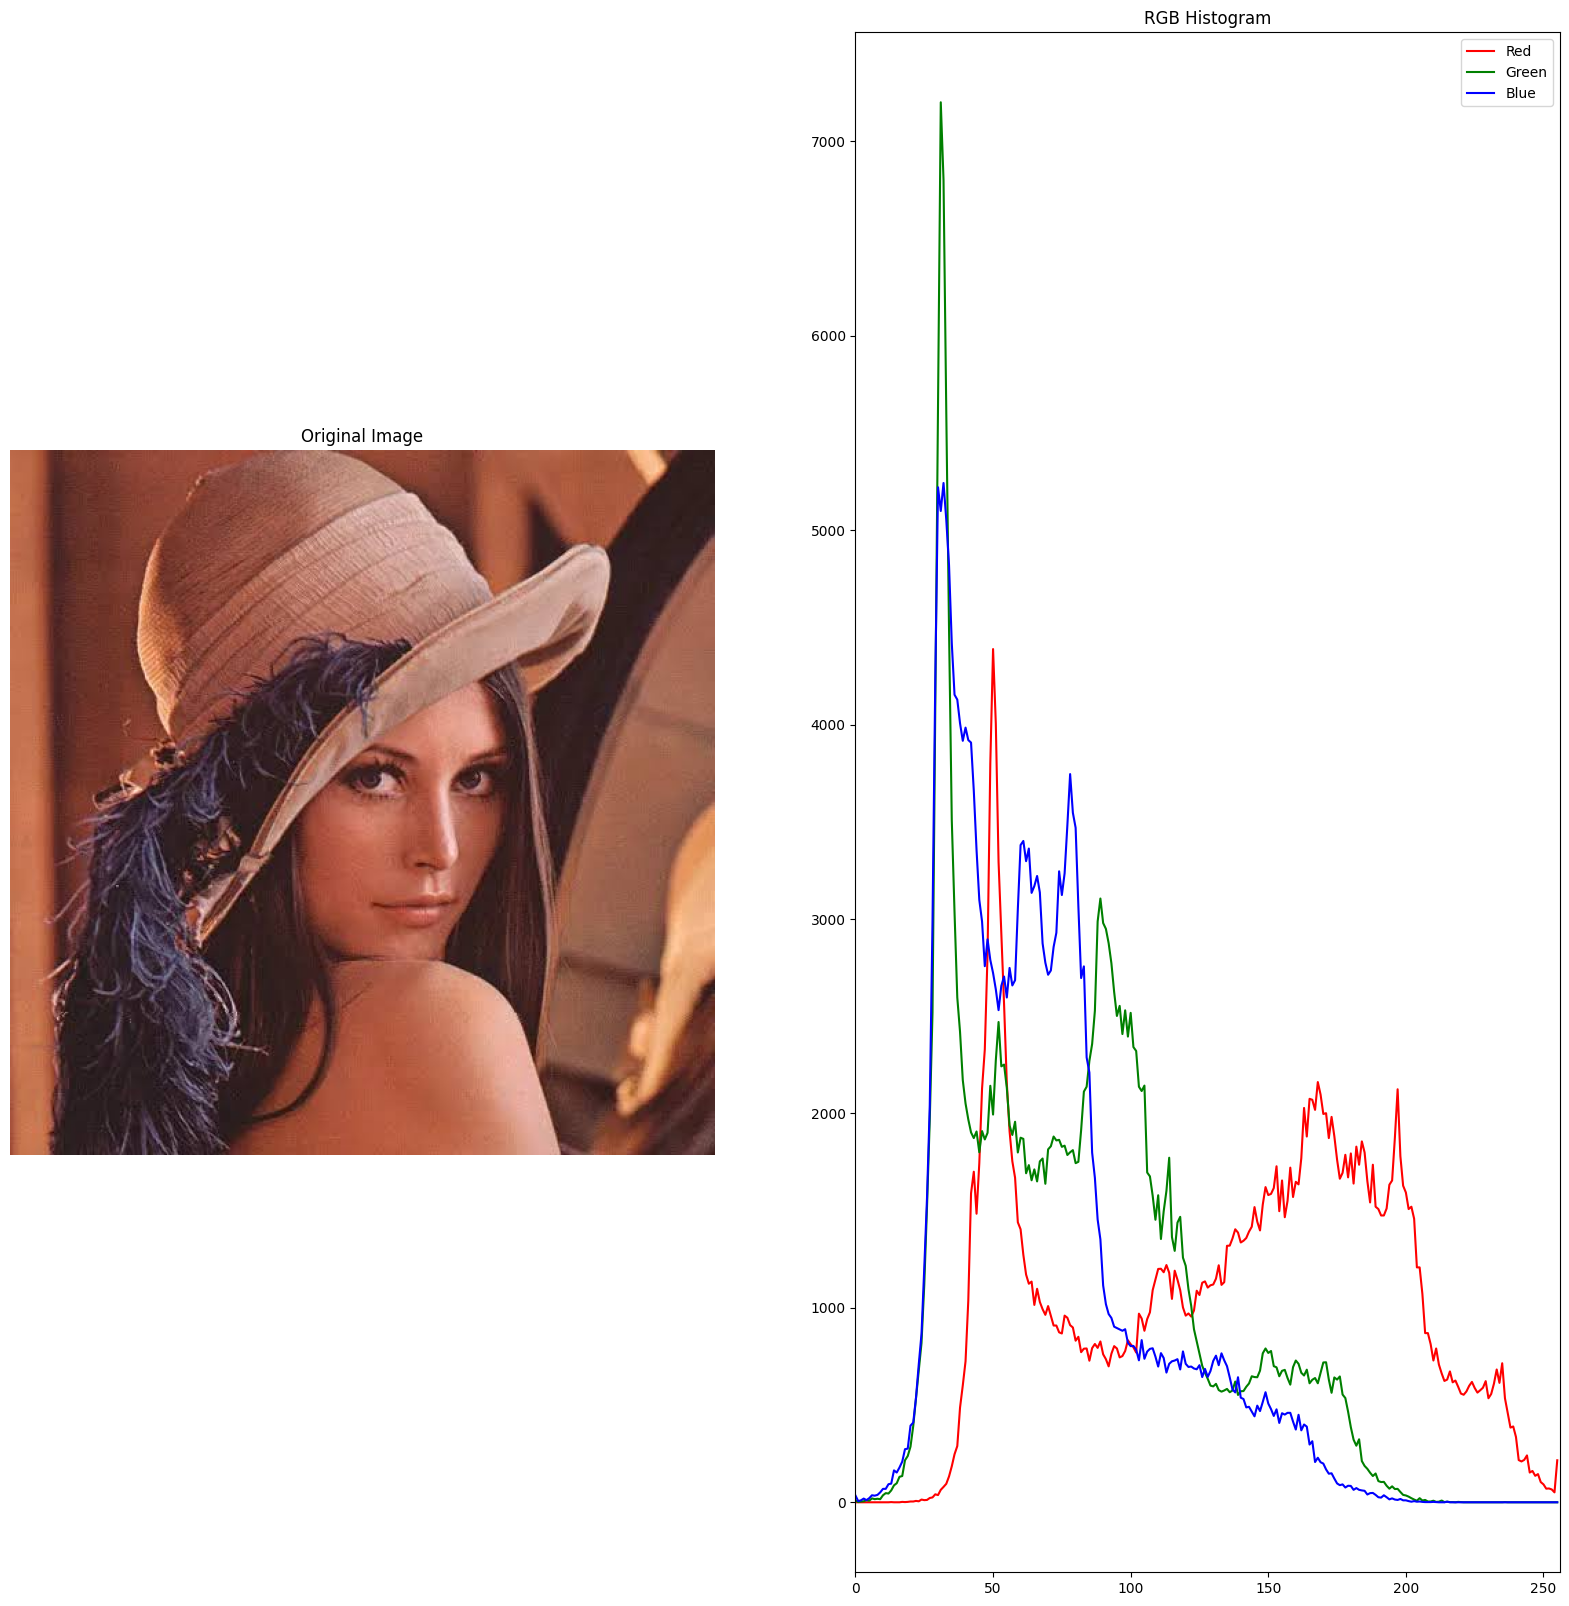

In [24]:
from google.colab.patches import cv2_imshow
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/gdrive')

img = cv2.imread('/content/gdrive/MyDrive/Image_processing/lena.jpg')
RGB_img1 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
R_img1, G_img1, B_img1 = cv2.split(RGB_img1)

plt.figure(figsize=(20, 20))
plt.subplot(1, 2, 1), plt.imshow(RGB_img1)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
hist_r = cv2.calcHist([R_img1], [0], None, [256], [0, 256])
hist_g = cv2.calcHist([G_img1], [0], None, [256], [0, 256])
hist_b = cv2.calcHist([B_img1], [0], None, [256], [0, 256])

plt.plot(hist_r, color='r', label='Red')
plt.plot(hist_g, color='g', label='Green')
plt.plot(hist_b, color='b', label='Blue')
plt.xlim([0, 256])
plt.title("RGB Histogram")
plt.legend()

plt.show()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


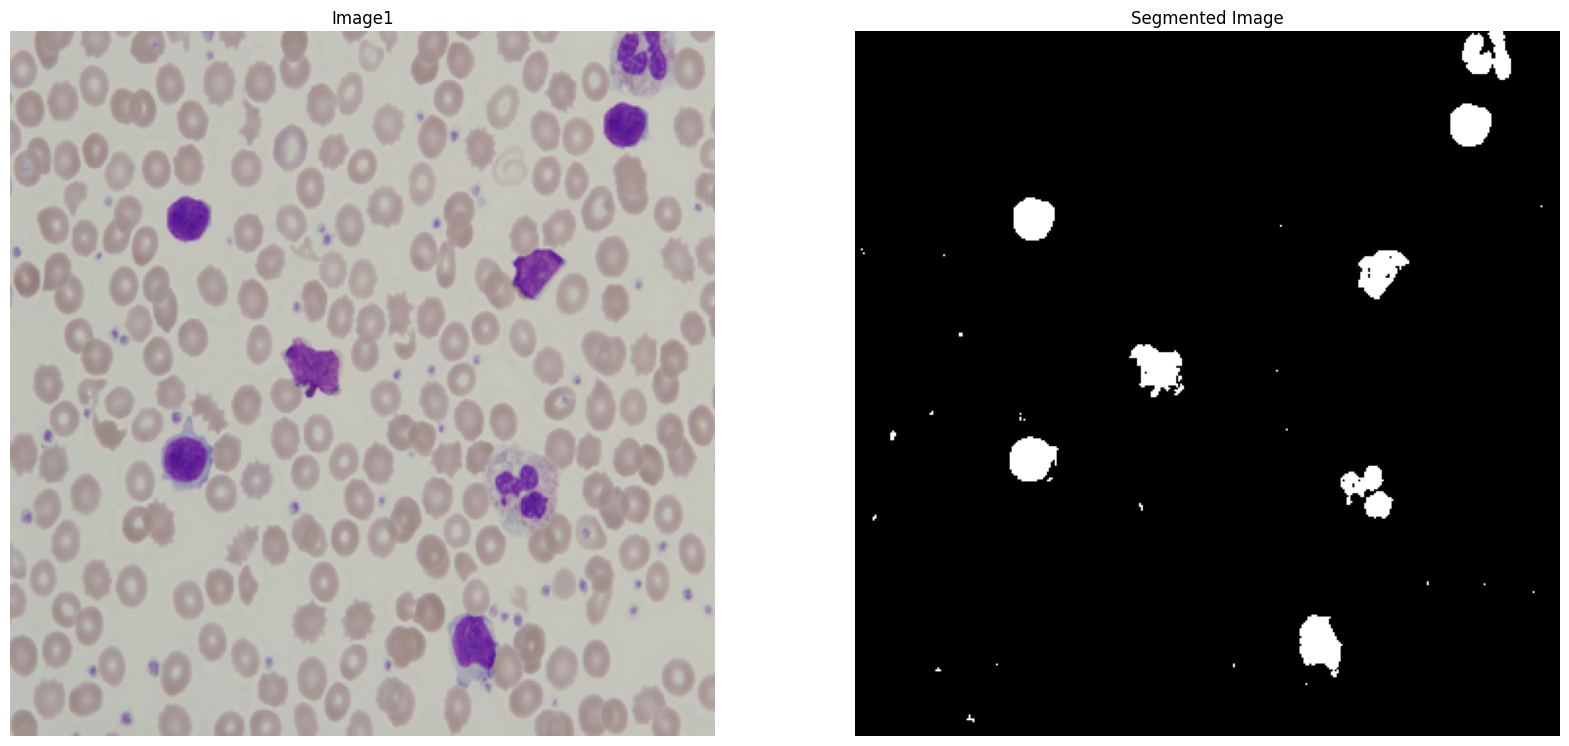

In [26]:
from google.colab.patches import cv2_imshow
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/gdrive')

# 실제 파일 위치인 구글 드라이브 루트 폴더로 경로 변경
img1 = cv2.imread('/content/gdrive/MyDrive/cell.bmp')

# 이미지 로드 확인 예외 처리
if img1 is None:
    raise FileNotFoundError("'/content/gdrive/MyDrive/cell.bmp' 경로에서 이미지를 찾을 수 없습니다. 경로를 확인해 주세요.")

RGB_img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

output_img = np.zeros((RGB_img1.shape[0], RGB_img1.shape[1]))

for h in range(RGB_img1.shape[0]):
    for w in range(RGB_img1.shape[1]):
        if(np.int32(RGB_img1[h,w][0])<140):
            output_img[h,w]=255
        else:
            output_img[h,w]=0

plt.figure(figsize=(20,20))
plt.subplot(1,2,1)
plt.title("Image1")
plt.imshow(RGB_img1)
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Segmented Image")
plt.imshow(output_img, cmap='gray')
plt.axis("off")

plt.show()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


/tmp/ipykernel_725/2836957559.py:27: RuntimeWarning: overflow encountered in scalar add
  sum1 = sum1 + img[h,w]
/tmp/ipykernel_725/2836957559.py:30: RuntimeWarning: overflow encountered in scalar add
  sum2 = sum2 + img[h,w]


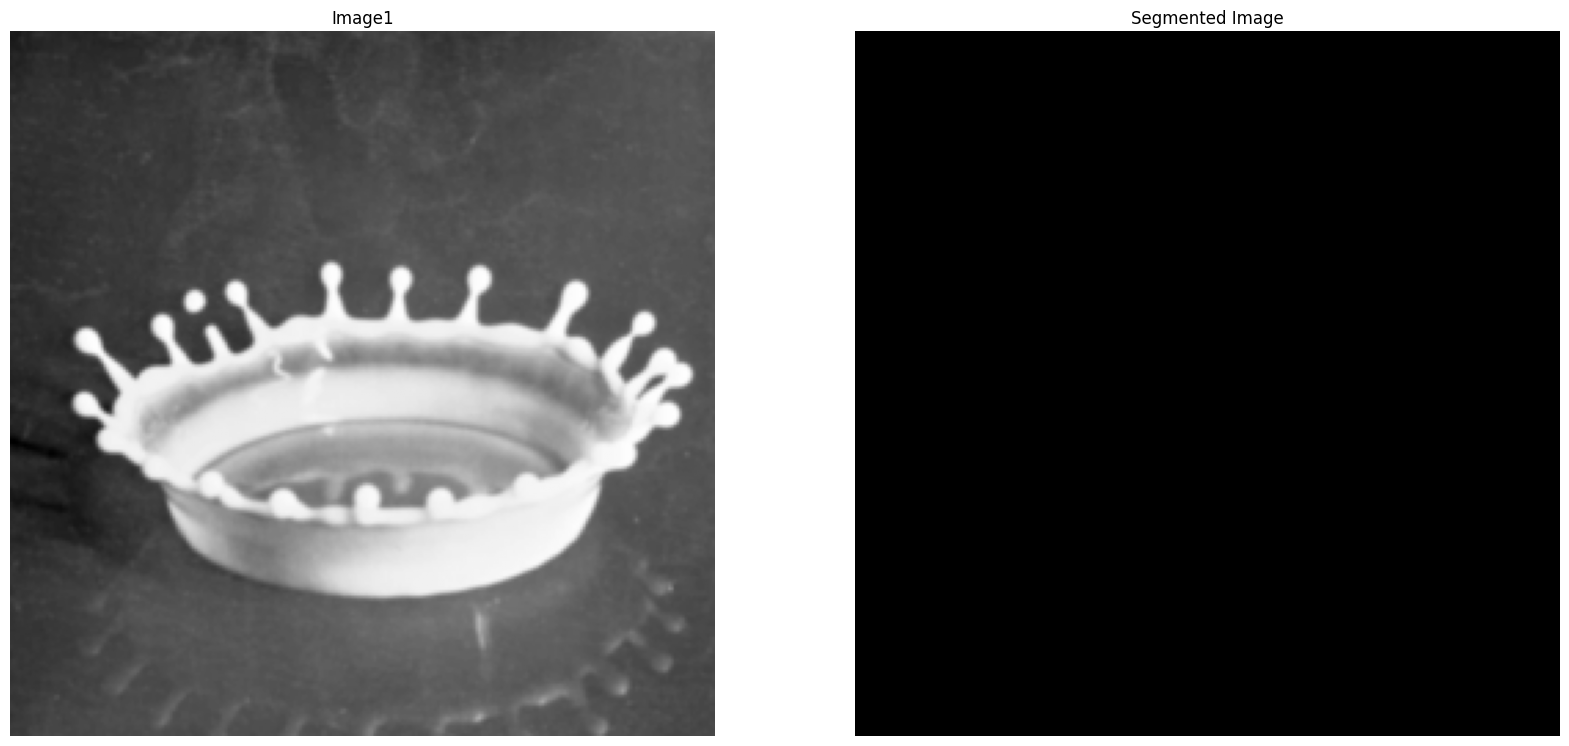

In [27]:
from google.colab.patches import cv2_imshow
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/gdrive')

img = cv2.imread('/content/gdrive/MyDrive/milkdrop.bmp')

gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

T1 = 50
T2 = 0
T0 = 1

output_img = np.zeros((gray_img.shape[0], gray_img.shape[1]))

def threshold_update(h, w, img, output, T1):
    sum1 = 0
    count1 = 1
    sum2 = 0
    count2 = 1
    for h in range(img.shape[0]):
        for w in range(img.shape[1]):
            if(output[h,w]==255):
                sum1 = sum1 + img[h,w]
                count1 = count1 + 1
            else:
                sum2 = sum2 + img[h,w]
                count2 = count2 + 1
    ave1 = sum1/count1
    ave2 = sum2/count2
    T2 = np.int32(ave1+ave2)/2
    return T2

for h in range(gray_img.shape[0]):
    for w in range(gray_img.shape[1]):
        if(gray_img[h,w]>T1):
            output_img[h,w]=255
        else:
            output_img[h,w]=0

while True:
    T2 = threshold_update(gray_img.shape[0], gray_img.shape[1], gray_img, output_img, T1)

    if(np.abs(T1-T2)<T0):
        for h in range(gray_img.shape[0]):
            for w in range(gray_img.shape[1]):
                if(gray_img[h,w]>T2):
                    output_img[h,w]=255
                else:
                    output_img[h,w]=0
        break
    else:
        T1 = T2
        for h in range(gray_img.shape[0]):
            for w in range(gray_img.shape[1]):
                if(gray_img[h,w]>T1):
                    output_img[h,w]=255
                else:
                    output_img[h,w]=0

plt.figure(figsize=(20,20))
plt.subplot(1,2,1)
plt.title("Image1")
plt.imshow(gray_img, cmap='gray')
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Segmented Image")
plt.imshow(output_img, cmap='gray')
plt.axis("off")

plt.show()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


/tmp/ipykernel_725/64503529.py:29: RuntimeWarning: overflow encountered in scalar add
  sum = sum+img[y,x]


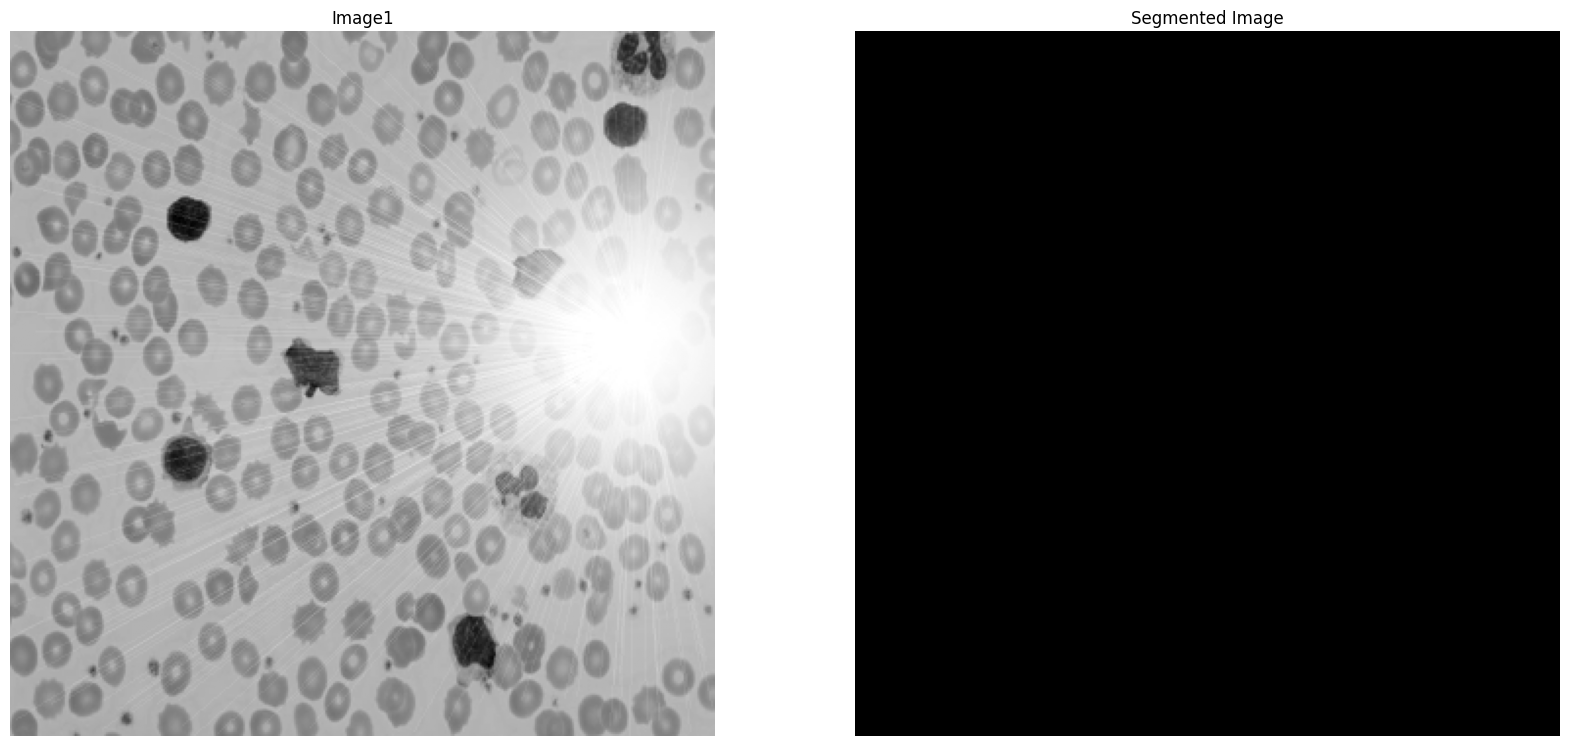

In [28]:
from google.colab.patches import cv2_imshow
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/gdrive')

img = cv2.imread('/content/gdrive/MyDrive/cell-bright.bmp')
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

N = 18

dimh = np.int32(gray_img.shape[0]/N)
dimw = np.int32(gray_img.shape[1]/N)

dh_rest = np.int32(gray_img.shape[0]%N)
dw_rest = np.int32(gray_img.shape[1]%N)

mean_img = np.zeros((N,N))
output_img = np.zeros((gray_img.shape[0], gray_img.shape[1]))

def mean_function(img,dimh,dimw,h,w):
    count=1
    sum=0
    ave=0
    for y in range(h, h+dimh):
        for x in range(w, w+dimw):
            sum = sum+img[y,x]
            count = count+1
    ave = np.int32(sum/count)
    return ave

for h in range(0,img.shape[0]-dh_rest,dimh):
    for w in range(0,img.shape[1]-dw_rest,dimw):
        if(h+dimh <img.shape[0] and w+dimw<img.shape[1]):
            mean_img[np.int32(h/dimh),np.int32(w/dimw)]= mean_function(gray_img,dimh,dimw,h,w)

for h in range(0,gray_img.shape[0]-dh_rest):
    for w in range(0,gray_img.shape[1]-dw_rest):
        if(gray_img[h,w]>= mean_img[np.int32(h/dimh),np.int32(w/dimw)]):
            output_img[h,w]=255
        else:
            output_img[h,w]=0

plt.figure(figsize=(20,20))
plt.subplot(1,2,1)
plt.title("Image1")
plt.imshow(gray_img, cmap='gray')
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Segmented Image")
plt.imshow(output_img, cmap='gray')
plt.axis("off")

plt.show()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


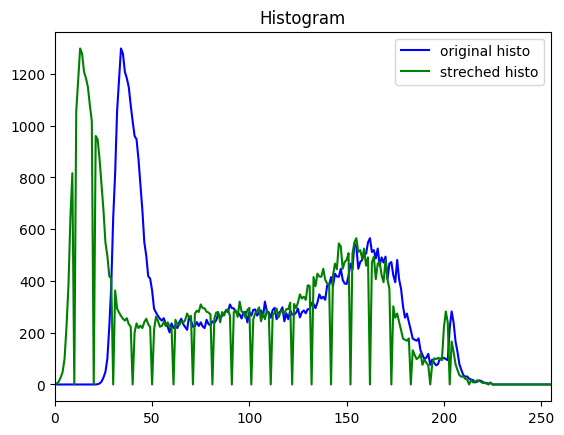

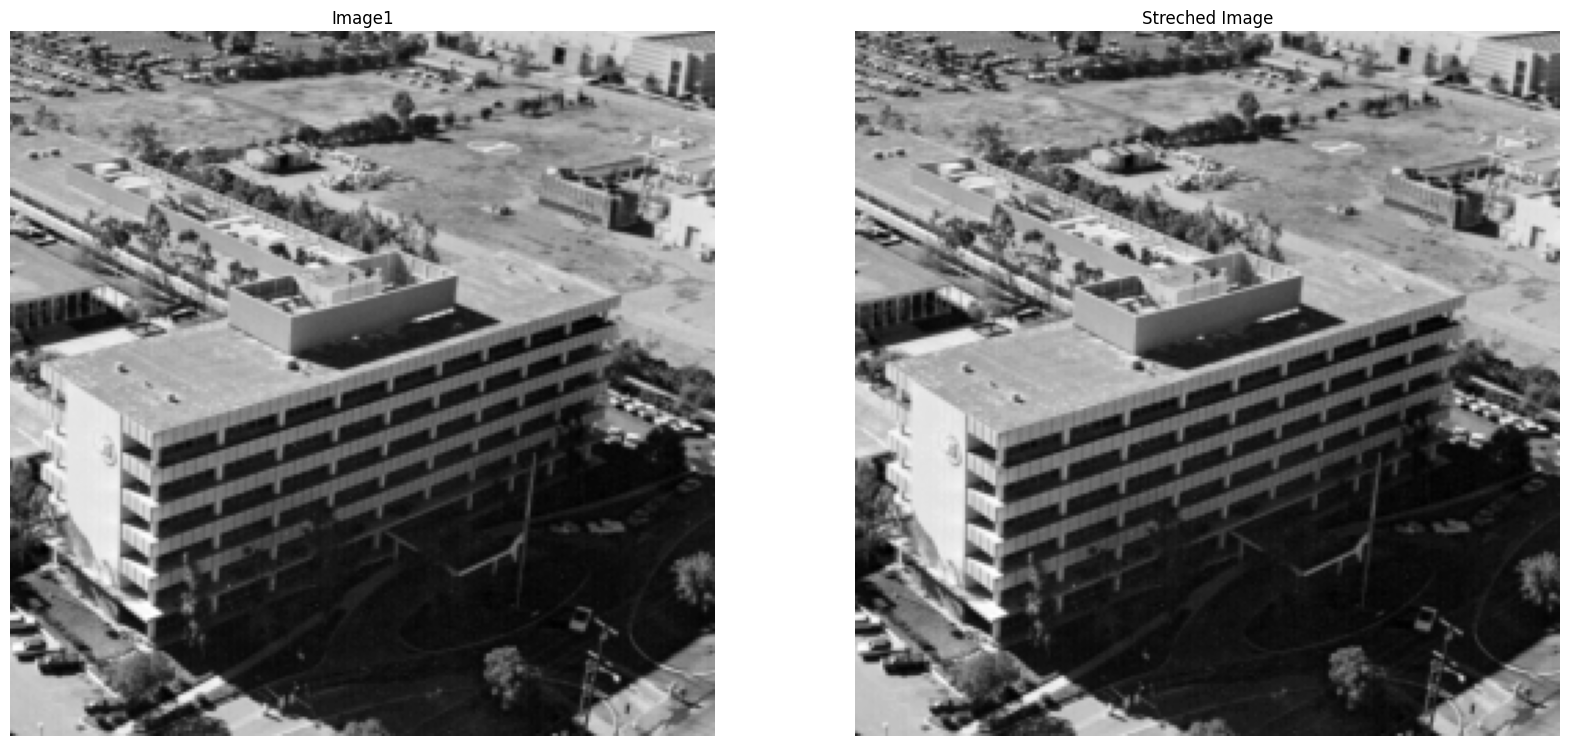

In [30]:
import matplotlib.pyplot as plt
from google.colab import drive
import numpy as np
import cv2

drive.mount('/content/gdrive')

img = cv2.imread('/content/gdrive/MyDrive/aero2.bmp')
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# 데이터 타입을 np.uint8로 명시적으로 설정하여 OpenCV 함수와의 호환성을 확보합니다.
output_img = np.zeros((gray_img.shape[0], gray_img.shape[1]), dtype=np.uint8)

def saturation(value):
    if(value>255):
        value = 255;
    return value

Nmax=255
Nmin=0
max = 0
min = 255

for h in range(img.shape[0]):
    for w in range(img.shape[1]):
        if (max < gray_img[h,w]):
            max = gray_img[h,w]
        if (min > gray_img[h,w]):
            min = gray_img[h,w]

for h in range(img.shape[0]):
    for w in range(img.shape[1]):
        if gray_img[h,w] < min:
            gray_img[h,w] = min
        if gray_img[h,w] > max:
            gray_img[h,w] = max

for h in range(img.shape[0]):
    for w in range(img.shape[1]):
        output_img[h,w] = saturation(np.int32((gray_img[h,w]-min)*np.float32(max-Nmin)/(max-min)+Nmin))

hist=cv2.calcHist([gray_img],[0],None,[256],[0,255])
plt.title("Histogram")
plt.plot(hist,color='b',label='original histo')
plt.xlim([0,255])
hist=cv2.calcHist([output_img],[0],None,[256],[0,255])
plt.plot(hist,color='g',label='streched histo')
plt.xlim([0,255])
plt.legend()

plt.figure(figsize=(20,20))
plt.subplot(1,2,1)
plt.title("Image1")
plt.imshow(gray_img, cmap='gray')
plt.axis("off")

plt.subplot(1,2,2)
plt.title("Streched Image")
plt.imshow(output_img, cmap='gray')
plt.axis("off")

plt.show()